load the dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

uploading dataset

In [ ]:
df = pd.read_csv("customer_churn_1M.csv")
df.head()

,customer_id,signup_date,age,gender,annual_income,education,marital_status,dependents,tenure,contract,...,has_streaming_tv,has_streaming_movies,customer_satisfaction,num_complaints,num_service_calls,late_payments,avg_monthly_gb,days_since_last_interaction,credit_score,churn
0,CUST0000000001,2022-12-12 12:53:58.199463,43.0,Female,55085.25,college,married,1.0,2.0,two_year,...,1.0,1.0,9.0,0.0,0.0,0.0,109.63,16.0,NaN,0.0
1,CUST0000000002,2022-01-13 12:53:58.199973,18.0,Male,60786.11,master,married,1.0,22.0,one_year,...,0.0,1.0,7.0,0.0,3.0,1.0,63.25,134.0,585.0,0.0
2,CUST0000000003,2023-09-04 12:53:58.199985,38.0,Female,73184.32,high_school,widowed,0.0,3.0,two_year,...,1.0,0.0,6.0,1.0,1.0,0.0,47.77,11.0,632.0,0.0
3,CUST0000000004,2022-06-27 12:53:58.199992,44.0,Male,40923.78,high_school,married,1.0,6.0,two_year,...,0.0,1.0,5.0,2.0,2.0,1.0,50.82,6.0,569.0,0.0
4,CUST0000000005,2022-12-08 12:53:58.199999,45.0,Female,36400.94,bachelor,single,0.0,9.0,two_year,...,0.0,1.0,8.0,1.0,1.0,0.0,16.74,18.0,657.0,0.0


check the dataset size



In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 79926
Columns: 32


Check column names

In [ ]:
print(df.columns.tolist())

['customer_id', 'signup_date', 'age', 'gender', 'annual_income', 'education', 'marital_status', 'dependents', 'tenure', 'contract', 'payment_method', 'paperless_billing', 'senior_citizen', 'monthlycharges', 'totalcharges', 'num_services', 'has_phone_service', 'has_internet_service', 'has_online_security', 'has_online_backup', 'has_device_protection', 'has_tech_support', 'has_streaming_tv', 'has_streaming_movies', 'customer_satisfaction', 'num_complaints', 'num_service_calls', 'late_payments', 'avg_monthly_gb', 'days_since_last_interaction', 'credit_score', 'churn']


check the datatypes and the missing values

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79926 entries, 0 to 79925
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   customer_id                  79926 non-null  object 
 1   signup_date                  79926 non-null  object 
 2   age                          79925 non-null  float64
 3   gender                       79925 non-null  object 
 4   annual_income                77531 non-null  float64
 5   education                    79925 non-null  object 
 6   marital_status               79925 non-null  object 
 7   dependents                   79925 non-null  float64
 8   tenure                       79925 non-null  float64
 9   contract                     79925 non-null  object 
 10  payment_method               79925 non-null  object 
 11  paperless_billing            79925 non-null  object 
 12  senior_citizen               79925 non-null  float64
 13  monthlycharges  

Check missing values

In [ ]:
df.isnull().sum()

,0
customer_id,0
signup_date,0
age,1
gender,1
annual_income,2395
education,1
marital_status,1
dependents,1
tenure,1
contract,1


check the target distribution

In [ ]:
print(df['churn'].value_counts())

churn
0.0    71945
1.0     7980
Name: count, dtype: int64


In [ ]:
print(df['churn'].value_counts(normalize=True) * 100)

churn
0.0    90.01564
1.0     9.98436
Name: proportion, dtype: float64


visualizing the churn disrtibution

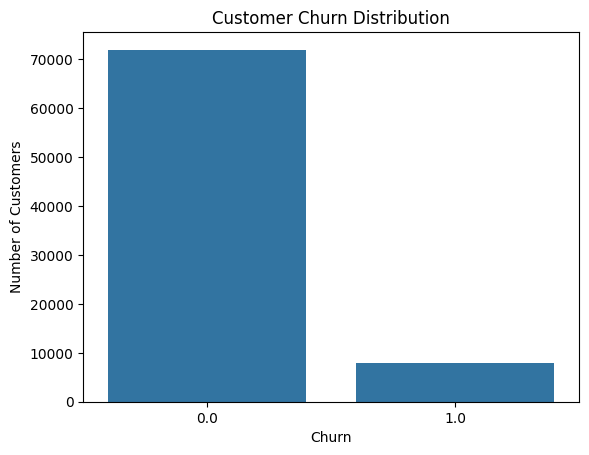

In [ ]:
sns.countplot(x='churn', data=df)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.show()

remove the unnecessary data

In [ ]:
df = df.drop(['customer_id', 'signup_date'], axis=1)

seperate input and output

In [ ]:
X = df.drop('churn', axis=1)
y = df['churn']

Identify numerical and categorical columns

In [ ]:
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

categorical_cols = X.select_dtypes(include=['object']).columns

In [ ]:
print("Numerical Columns:")
print(list(numerical_cols))

print("\nCategorical Columns:")
print(list(categorical_cols))

Numerical Columns:
['age', 'annual_income', 'dependents', 'tenure', 'senior_citizen', 'monthlycharges', 'totalcharges', 'num_services', 'has_phone_service', 'has_internet_service', 'has_online_security', 'has_online_backup', 'has_device_protection', 'has_tech_support', 'has_streaming_tv', 'has_streaming_movies', 'customer_satisfaction', 'num_complaints', 'num_service_calls', 'late_payments', 'avg_monthly_gb', 'days_since_last_interaction', 'credit_score']

Categorical Columns:
['gender', 'education', 'marital_status', 'contract', 'payment_method', 'paperless_billing']


In [ ]:
print(df['churn'].isnull().sum())

1


In [ ]:
df = df.dropna(subset=['churn'])

In [ ]:
print(df['churn'].isnull().sum())

0


In [ ]:
X = df.drop('churn', axis=1)
y = df['churn']

split the dataset

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

create data for preprocessing

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

numerical preprocessing

In [ ]:
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical preprocessing

In [ ]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

combine preprocessing

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

create a logistic regression model

In [ ]:
from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000
    ))
])

train the model

In [ ]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['age', 'annual_income', 'dependents', 'tenure', 'senior_citizen',
       'monthlycharges', 'totalcharges', 'num_services', 'has_phone_service',
       'has_internet_service', 'has_online_security', 'has_onl...
       'days_since_last_interaction', 'credit_score'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['gender', 'education', 'marital_status', 'contract', 'payment_method',
       'paperless_billing'],
      dtype='object'))])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

make predictions

In [ ]:
y_pred = model.predict(X_test)

some predicitons

In [ ]:
print("Actual:")
print(y_test.values[:20])
print("\nPredicted:")
print(y_pred[:20])

Actual:
[1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Predicted:
[0. 1. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 1. 1.]


accurancy report

In [ ]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.6258992805755396
Accuracy (%): 62.589928057553955


classifiction report

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(
    y_test,
    y_pred,
    target_names=['Not Churn', 'Churn']
))

              precision    recall  f1-score   support

   Not Churn       0.94      0.62      0.75     14389
       Churn       0.16      0.64      0.25      1596

    accuracy                           0.63     15985
   macro avg       0.55      0.63      0.50     15985
weighted avg       0.86      0.63      0.70     15985



Confusion matrix

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[8988 5401]
 [ 579 1017]]


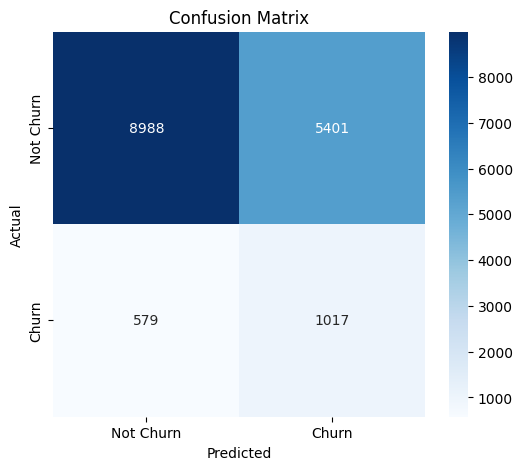

In [ ]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Churn', 'Churn'],
    yticklabels=['Not Churn', 'Churn']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

precesion,recall and f1 seperately

In [ ]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.15846057961981927
Recall: 0.6372180451127819
F1 Score: 0.25380583978038435


ROC and AUC

In [ ]:
y_prob = model.predict_proba(X_test)[:, 1]

In [ ]:
from sklearn.metrics import roc_auc_score
roc_auc = roc_auc_score(y_test, y_prob)
print("ROC-AUC:", roc_auc)

ROC-AUC: 0.6822672080855415


ROC curve


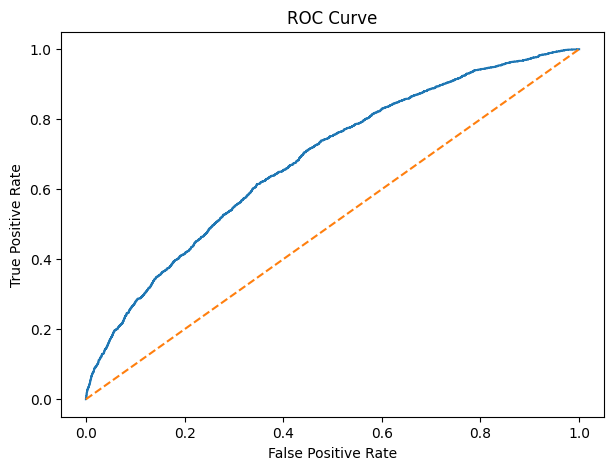

In [ ]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')

plt.show()

Test one customers predictions

In [ ]:
customer = X_test.iloc[[0]]

prediction = model.predict(customer)
probability = model.predict_proba(customer)[0][1]

print("Prediction:", prediction[0])
print("Churn Probability:", probability)

Prediction: 0.0
Churn Probability: 0.42992249657011994


In [ ]:
if prediction[0] == 1:
    print("Customer is predicted to CHURN")
else:
    print("Customer is predicted to NOT CHURN")

Customer is predicted to NOT CHURN


save the trained model

In [ ]:
import joblib
joblib.dump(model, 'customer_churn_logistic_regression.pkl')

['customer_churn_logistic_regression.pkl']